# Exploratory Data Analysis (EDA)

## Import library

In [1]:
import duckdb
import pandas as pd
import numpy as np
import json
import plotly.express as px
import matplotlib.pyplot as plt
from pathlib import Path

### Set folders

In [2]:
PROCESSED_DIR = Path("../data/processed")
REFERENCE_DIR = Path("../data/reference")

### Connect DuckDB and load cleaned data

In [3]:
con = duckdb.connect()

con.execute(f"""
    CREATE OR REPLACE VIEW rideshare AS
    SELECT *
    FROM read_parquet('{PROCESSED_DIR}/rideshare_2025_clean.parquet')
""")

## EDA follow by pickup community area

In [4]:
pickup_area_summary = con.sql("""
    SELECT
        pickup_community_area,
        COUNT(*) AS trip_count,
        AVG(fare) AS avg_fare,
        AVG(trip_miles) AS avg_trip_miles,
        AVG(trip_seconds) / 60 AS avg_trip_minutes
    FROM rideshare
    WHERE pickup_community_area BETWEEN 1 AND 77
    GROUP BY pickup_community_area
    ORDER BY pickup_community_area
""").df()

### Load Chicago community areas GeoJSON

In [5]:
with open(
    REFERENCE_DIR / "community_areas.geojson", "r"
) as f:
    chicago_geojson = json.load(f)

### Create community name lookup

In [6]:
community_names = {
    int(feature["properties"]["area_numbe"]):
    feature["properties"]["community"].title()
    for feature in chicago_geojson["features"]
}

pickup_area_summary["community"] = (
    pickup_area_summary["pickup_community_area"]
    .map(community_names)
)

### Log Scale for Better Color Contrast

Because the trip count data is highly skewed, I applied a log transformation to improve the color contrast on the map and make differences between community areas easier to see.

In [7]:
pickup_area_summary["log_trip_count"] = np.log10(pickup_area_summary["trip_count"])

### Create interactive choropleth map

### Trip count by pickup community area

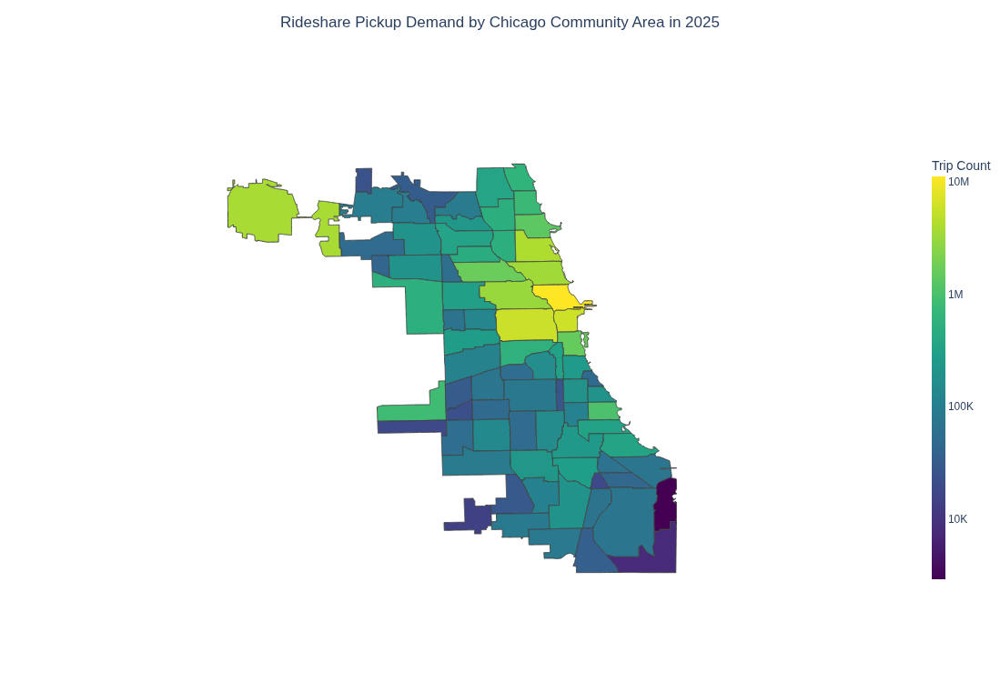

In [8]:
fig = px.choropleth(
    pickup_area_summary,
    geojson=chicago_geojson,
    locations="pickup_community_area",
    featureidkey="properties.area_numbe",
    color="log_trip_count",
    hover_name="community",
    hover_data={
        "pickup_community_area": True,
        "trip_count": ":,",
        "avg_fare": ":.2f",
        "avg_trip_miles": ":.2f",
        "log_trip_count": False
    },
    color_continuous_scale="Viridis",
    labels={
        "pickup_community_area": "Community Area",
        "trip_count": "Trip Count",
        "avg_fare": "Average Fare",
        "avg_trip_miles": "Average Trip Miles",
        "log_trip_count": "Trip Demand"
    },
    title="Rideshare Pickup Demand by Chicago Community Area in 2025"
)

fig.update_geos(
    fitbounds="locations",
    visible=False
)

fig.update_layout(
    coloraxis_colorbar=dict(
        title="Trip Count",
        tickvals=[4, 5, 6, 7],
        ticktext=["10K", "100K", "1M", "10M"],
        thickness=15,
        len=0.7
    ),
    title=dict(
        x=0.5,
        xanchor="center"
    ),
    margin=dict(l=0, r=0, t=60, b=0),
    height=750
)


fig.show()

Ride demand is not evenly distributed across Chicago. The map shows that pickup activity is concentrated in several central and northern community areas, while many areas farther from the city center have lower trip counts. O'Hare also shows relatively high pickup demand, which is expected because the airport generates a large number of rides. This suggests that location may be an important factor when analyzing ride demand and fare patterns.

### Average rideshare fare by community area

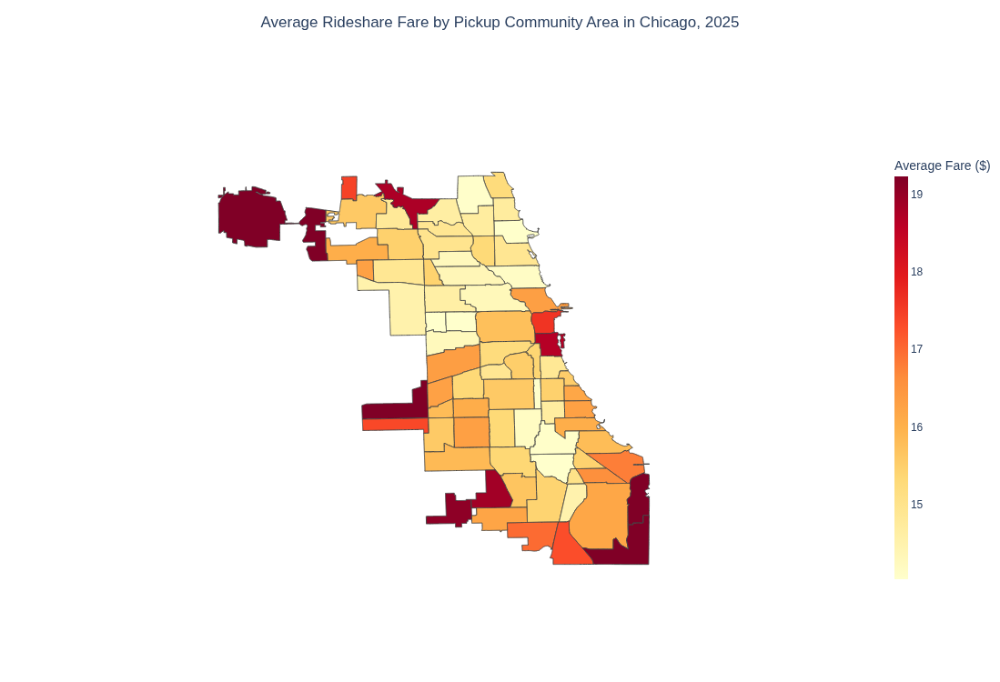

In [9]:
lower = pickup_area_summary["avg_fare"].quantile(0.05)
upper = pickup_area_summary["avg_fare"].quantile(0.95)

fig = px.choropleth(
    pickup_area_summary,
    geojson=chicago_geojson,
    locations="pickup_community_area",
    featureidkey="properties.area_numbe",
    color="avg_fare",
    hover_name="community",
    hover_data={
        "pickup_community_area": True,
        "trip_count": ":,",
        "avg_fare": ":.2f",
        "avg_trip_miles": ":.2f"
    },
    color_continuous_scale="YlOrRd",
    range_color = (lower, upper),
    labels={
        "pickup_community_area": "Community Area",
        "trip_count": "Trip Count",
        "avg_fare": "Average Fare ($)",
        "avg_trip_miles": "Average Trip Miles"
    },
    title="Average Rideshare Fare by Pickup Community Area in Chicago, 2025"
)

fig.update_geos(
    fitbounds="locations",
    visible=False
)

fig.update_layout(
    coloraxis_colorbar=dict(
        title="Average Fare ($)",
        thickness=15,
        len=0.7
    ),
    title=dict(
        x=0.5,
        xanchor="center"
    ),
    margin=dict(
        l=0,
        r=0,
        t=60,
        b=0
    ),
    height=750
)

fig.show()

## EDA by Hour

To examine how rideshare activity and pricing change throughout the day, I aggregated the trips by pickup hour and calculated the number of trips, average fare, average trip distance, and average trip duration.

In [10]:
hourly_summary = con.sql("""
    SELECT
        EXTRACT(HOUR FROM trip_start_timestamp) AS hour,
        COUNT(*) AS trip_count,
        ROUND(AVG(fare), 2) AS avg_fare,
        ROUND(AVG(trip_miles), 2) AS avg_trip_miles,
        ROUND(AVG(trip_seconds) / 60, 2) AS avg_trip_minutes
    FROM rideshare
    GROUP BY hour
    ORDER BY hour
""").df()

display(hourly_summary)

,hour,trip_count,avg_fare,avg_trip_miles,avg_trip_minutes
0,0,1755265,15.91,5.35,13.50
1,1,1144714,15.63,5.04,12.73
2,2,664255,16.62,4.97,12.41
3,3,354843,17.14,6.24,13.49
4,4,278822,24.29,10.39,17.75
5,5,473315,27.20,11.98,21.83
6,6,933376,22.23,9.37,21.21
7,7,1594141,20.54,7.25,21.07
8,8,2360661,19.38,6.28,19.34
9,9,2552125,16.70,6.38,17.61


### Trip Demand by Hour

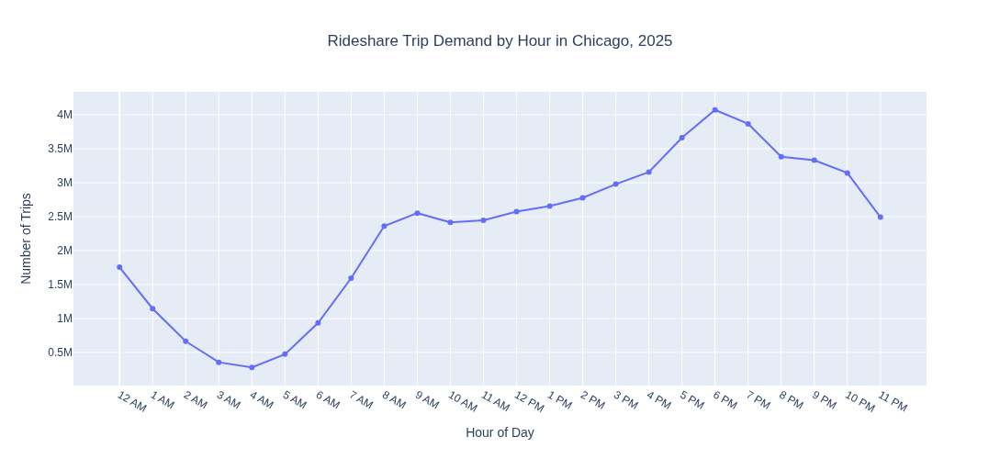

In [11]:
fig = px.line(
    hourly_summary,
    x="hour",
    y="trip_count",
    markers=True,
    title="Rideshare Trip Demand by Hour in Chicago, 2025",
    labels={
        "hour": "Hour of Day",
        "trip_count": "Number of Trips"
    }
)

fig.update_xaxes(
    tickmode="array",
    tickvals=list(range(24)),
    ticktext=[
        "12 AM", "1 AM", "2 AM", "3 AM", "4 AM", "5 AM",
        "6 AM", "7 AM", "8 AM", "9 AM", "10 AM", "11 AM",
        "12 PM", "1 PM", "2 PM", "3 PM", "4 PM", "5 PM",
        "6 PM", "7 PM", "8 PM", "9 PM", "10 PM", "11 PM"
    ]
)

fig.update_layout(
    title=dict(
        x=0.5,
        xanchor="center"
    ),
    height=500
)

fig.show()

Ride demand changes substantially throughout the day. Demand is lowest around 4 AM with about 279,000 trips, then increases rapidly during the morning and continues rising throughout the afternoon. The highest demand occurs around 6 PM with approximately 4.07 million trips, after which demand gradually decreases through the evening. This pattern suggests that time of day is an important factor in rideshare demand.

### Average Fare by Hour

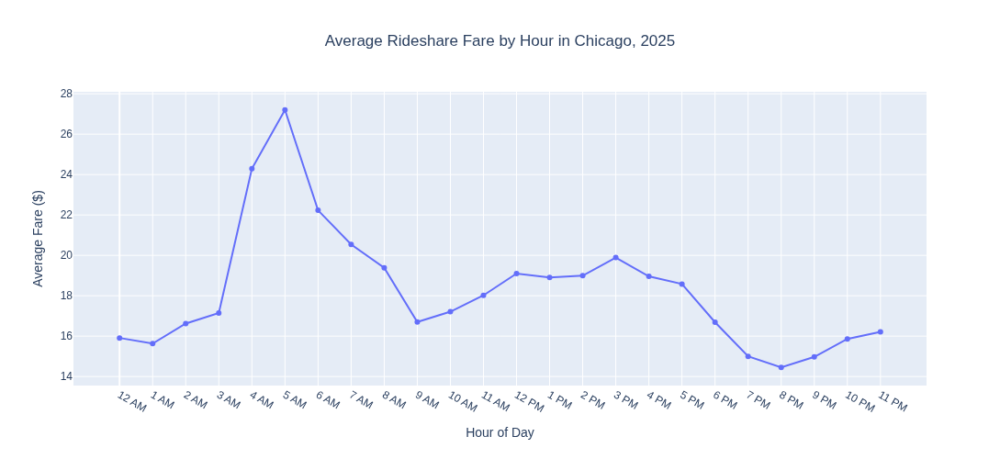

In [12]:
fig = px.line(
    hourly_summary,
    x="hour",
    y="avg_fare",
    markers=True,
    title="Average Rideshare Fare by Hour in Chicago, 2025",
    labels={
        "hour": "Hour of Day",
        "avg_fare": "Average Fare ($)"
    }
)

fig.update_xaxes(
    tickmode="array",
    tickvals=list(range(24)),
    ticktext=[
        "12 AM", "1 AM", "2 AM", "3 AM", "4 AM", "5 AM",
        "6 AM", "7 AM", "8 AM", "9 AM", "10 AM", "11 AM",
        "12 PM", "1 PM", "2 PM", "3 PM", "4 PM", "5 PM",
        "6 PM", "7 PM", "8 PM", "9 PM", "10 PM", "11 PM"
    ]
)

fig.update_layout(
    title=dict(
        x=0.5,
        xanchor="center"
    ),
    height=500
)

fig.show()

Average fare follows a different pattern from trip demand. The highest average fare occurs around 5 AM at \$$27.20, while demand at that time is relatively low. In comparison, the peak-demand period around 6 PM has an average fare of only \$16.69. The 5 AM trips also have a much higher average distance of about 11.98 miles, suggesting that the high early-morning fare may be driven more by longer trips than by high demand. Therefore, demand alone does not appear to explain hourly fare variation, and trip distance and duration should be controlled for in the later analysis.

### Fare vs trip distance

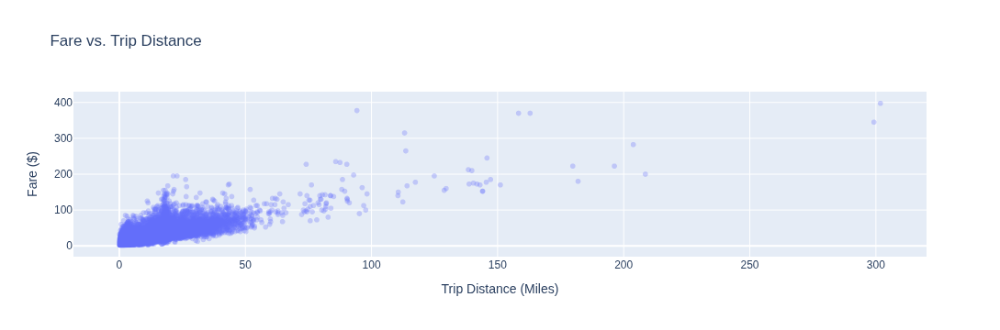

In [13]:
sample_df = con.sql("""
    SELECT
        trip_miles,
        fare
    FROM rideshare
    WHERE trip_miles > 0
      AND fare > 0
    USING SAMPLE 100000 ROWS
""").df()

fig = px.scatter(
    sample_df,
    x="trip_miles",
    y="fare",
    opacity=0.3,
    title="Fare vs. Trip Distance",
    labels={
        "trip_miles": "Trip Distance (Miles)",
        "fare": "Fare ($)"
    }
)

fig.show()

The scatter plot shows a clear positive relationship between trip distance and fare. As trip distance increases, the fare generally increases as well. Most trips are concentrated at shorter distances and lower fares, while a small number of trips have unusually long distances or high fares. This suggests that trip distance is an important factor when analyzing rideshare pricing and should be controlled for when examining the effect of demand on fare.

### Fare vs Hourly Demand

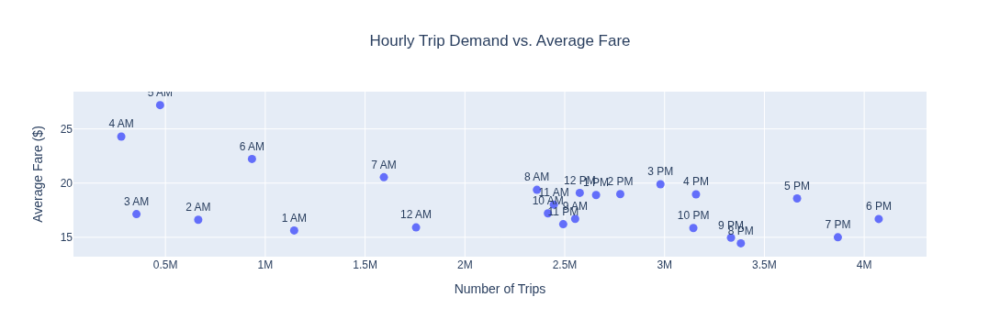

In [15]:
hourly_summary["hour_label"] = hourly_summary["hour"].apply(
    lambda h: (
        "12 AM" if h == 0
        else "12 PM" if h == 12
        else f"{h} AM" if h < 12
        else f"{h - 12} PM"
    )
)

fig = px.scatter(
    hourly_summary,
    x="trip_count",
    y="avg_fare",
    text="hour_label",
    hover_name="hour_label",
    hover_data={
        "trip_count": ":,",
        "avg_fare": ":.2f",
        "avg_trip_miles": ":.2f",
        "avg_trip_minutes": ":.2f",
        "hour": False
    },
    title="Hourly Trip Demand vs. Average Fare",
    labels={
        "trip_count": "Number of Trips",
        "avg_fare": "Average Fare ($)"
    }
)

fig.update_traces(
    textposition="top center",
    marker=dict(size=9)
)

fig.update_layout(
    title=dict(
        x=0.5,
        xanchor="center"
    )
)

fig.show()

The scatter plot shows that hourly trip demand and average fare do not have a simple positive relationship. The highest average fares occur during the early morning hours, especially around 4–6 AM, when trip demand is relatively low. In contrast, the highest-demand hours, around 5–7 PM, have lower average fares.

This suggests that demand alone does not explain fare differences across the day. Other factors, such as trip distance and duration, likely contribute to the higher fares observed during low-demand early morning hours. Therefore, these variables should be controlled for when analyzing the effect of demand on rideshare pricing.